In [285]:
import numpy as np 
import pandas as pd 
import plotly.graph_objects as go
import plotly.express as px
import plotly
import re
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
print('modules are imported')

modules are imported


In [288]:
df_24 = pd.read_csv('male_players.csv', on_bad_lines='skip', low_memory=False)

In [289]:
df_24.head()

,player_id,player_url,fifa_version,fifa_update,update_as_of,short_name,long_name,player_positions,overall,potential,...,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk
0,231747,/player/231747/kylian-mbappe/240002,24.0,2.0,2023-09-22,K. Mbappé,Kylian Mbappé Lottin,"ST, LW",91,94,...,63+3,63+3,63+3,68+3,63+3,54+3,54+3,54+3,63+3,18+3
1,239085,/player/239085/erling-haaland/240002,24.0,2.0,2023-09-22,E. Haaland,Erling Braut Haaland,ST,91,94,...,63+3,63+3,63+3,62+3,60+3,62+3,62+3,62+3,60+3,19+3
2,192985,/player/192985/kevin-de-bruyne/240002,24.0,2.0,2023-09-22,K. De Bruyne,Kevin De Bruyne,"CM, CAM",91,91,...,80+3,80+3,80+3,79+3,75+3,70+3,70+3,70+3,75+3,21+3
3,158023,/player/158023/lionel-messi/240002,24.0,2.0,2023-09-22,L. Messi,Lionel Andrés Messi Cuccittini,"CF, CAM",90,90,...,63+3,63+3,63+3,64+3,59+3,49+3,49+3,49+3,59+3,19+3
4,165153,/player/165153/karim-benzema/240002,24.0,2.0,2023-09-22,K. Benzema,Karim Benzema,"CF, ST",90,90,...,64+3,64+3,64+3,64+3,60+3,55+3,55+3,55+3,60+3,18+3


In [290]:
df_24.shape

(180021, 109)

In [291]:
cols = list(df_24.columns)
print(cols)

['player_id', 'player_url', 'fifa_version', 'fifa_update', 'update_as_of', 'short_name', 'long_name', 'player_positions', 'overall', 'potential', 'value_eur', 'wage_eur', 'age', 'dob', 'height_cm', 'weight_kg', 'club_team_id', 'club_name', 'league_id', 'league_name', 'league_level', 'club_position', 'club_jersey_number', 'club_loaned_from', 'club_joined_date', 'club_contract_valid_until_year', 'nationality_id', 'nationality_name', 'nation_team_id', 'nation_position', 'nation_jersey_number', 'preferred_foot', 'weak_foot', 'skill_moves', 'international_reputation', 'work_rate', 'body_type', 'real_face', 'release_clause_eur', 'player_tags', 'player_traits', 'pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'attacking_crossing', 'attacking_finishing', 'attacking_heading_accuracy', 'attacking_short_passing', 'attacking_volleys', 'skill_dribbling', 'skill_curve', 'skill_fk_accuracy', 'skill_long_passing', 'skill_ball_control', 'movement_acceleration', 'movement_sprint_speed'

In [292]:
useless_columns = ['dob','player_id', 'player_url', 'long_name', 'real_face', 'nation_position', 'nation_jersey_number', 'fifa_update', 'update_as_of', 'club_team_id', 'league_id', 'club_loaned_from', 'club_joined_date', 'nationality_id', 'nation_team_id']
df_clean = df_24.drop(useless_columns, axis=1)

In [293]:
df_clean['BMI']=df_clean['weight_kg']/(df_clean['height_cm']/100)**2
df_clean.head()

,fifa_version,short_name,player_positions,overall,potential,value_eur,wage_eur,age,height_cm,weight_kg,...,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk,BMI
0,24.0,K. Mbappé,"ST, LW",91,94,181500000.0,230000.0,24,182,75,...,63+3,63+3,68+3,63+3,54+3,54+3,54+3,63+3,18+3,22.642193
1,24.0,E. Haaland,ST,91,94,185000000.0,340000.0,22,195,94,...,63+3,63+3,62+3,60+3,62+3,62+3,62+3,60+3,19+3,24.720579
2,24.0,K. De Bruyne,"CM, CAM",91,91,103000000.0,350000.0,32,181,75,...,80+3,80+3,79+3,75+3,70+3,70+3,70+3,75+3,21+3,22.893074
3,24.0,L. Messi,"CF, CAM",90,90,41000000.0,23000.0,36,169,67,...,63+3,63+3,64+3,59+3,49+3,49+3,49+3,59+3,19+3,23.458562
4,24.0,K. Benzema,"CF, ST",90,90,51000000.0,95000.0,35,185,81,...,64+3,64+3,64+3,60+3,55+3,55+3,55+3,60+3,18+3,23.666910


In [294]:
print(df_clean['BMI'].dtype)

float64


In [295]:
df_clean[['short_name','player_positions']]

,short_name,player_positions
0,K. Mbappé,"ST, LW"
1,E. Haaland,ST
2,K. De Bruyne,"CM, CAM"
3,L. Messi,"CF, CAM"
4,K. Benzema,"CF, ST"
...,...,...
180016,E. Redman,CB
180017,A. Collins,ST
180018,P. Żemło,"LM, LB"
180019,T. Davies,CB


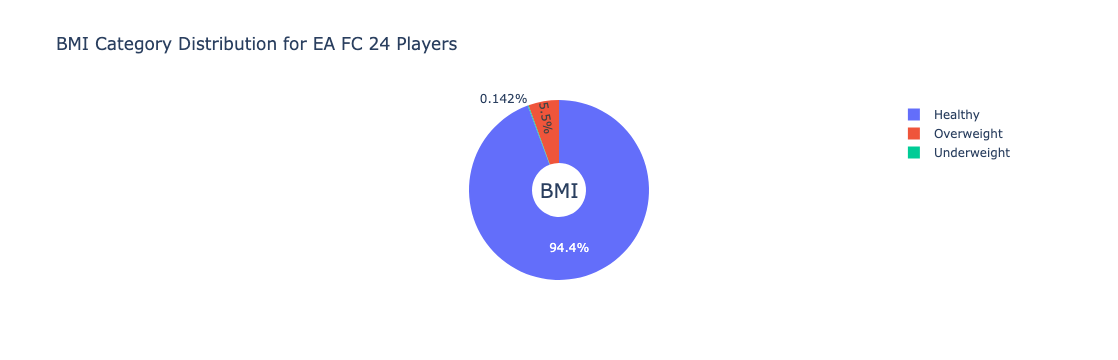

,short_name,overall,BMI
32,M. Neuer,87,24.967113
60,S. Milinković-Savić,86,25.770399
42,M. de Ligt,86,24.915316
72,A. Onana,85,25.761773
82,J. Grealish,85,25.000000


In [300]:
df_clean['BMI_category'] = pd.cut(
    df_clean['BMI'],
    bins=[0, 18.5, 24.9, float('inf')],
    labels=['Underweight', 'Healthy', 'Overweight']
)

df_24_clean = df_clean[df_clean['fifa_version'] == 24.0].copy()

bmi_counts = df_24_clean['BMI_category'].value_counts()

fig = go.Figure(data=[go.Pie(labels=bmi_counts.index, values=bmi_counts.values, hole=.3)])
fig.update_layout(
    title_text="BMI Category Distribution for EA FC 24 Players",
    annotations=[dict(text='BMI', x=0.5, y=0.5, font_size=20, showarrow=False)]
)
fig.show()

top_overweight = df_24_clean[df_24_clean['BMI_category'] == 'Overweight'].sort_values(
    by='overall', ascending=False
).head(5)

top_overweight[['short_name', 'overall', 'BMI']]

In [301]:
new_player_positions=df_24_clean['player_positions'].str.get_dummies(sep = ', ').add_prefix('Position_')
new_player_positions.head()

,Position_CAM,Position_CB,Position_CDM,Position_CF,Position_CM,Position_GK,Position_LB,Position_LM,Position_LW,Position_LWB,Position_RB,Position_RM,Position_RW,Position_RWB,Position_ST
0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
2,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
3,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1


In [302]:
df_clean=pd.concat([df_clean,new_player_positions],axis=1)

In [303]:
df_clean = df_clean.drop('player_positions',axis=1)

In [304]:
columns = ['ls', 'st', 'rs', 'lw', 'lf', 'cf', 'rf', 'rw', 'lam', 'cam', 'ram',
       'lm', 'lcm', 'cm', 'rcm', 'rm', 'lwb', 'ldm', 'cdm', 'rdm', 'rwb', 'lb',
       'lcb', 'cb', 'rcb', 'rb', 'gk']

In [305]:
df_clean[columns].head()

,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,...,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk
0,90+3,90+3,90+3,91,91,91,91,91,89+3,89+3,...,63+3,63+3,63+3,68+3,63+3,54+3,54+3,54+3,63+3,18+3
1,90+3,90+3,90+3,82,86,86,86,82,82+3,82+3,...,63+3,63+3,63+3,62+3,60+3,62+3,62+3,62+3,60+3,19+3
2,83+3,83+3,83+3,87,88,88,88,87,89+2,89+2,...,80+3,80+3,80+3,79+3,75+3,70+3,70+3,70+3,75+3,21+3
3,85+3,85+3,85+3,90,89,89,89,90,91-1,91-1,...,63+3,63+3,63+3,64+3,59+3,49+3,49+3,49+3,59+3,19+3
4,88+2,88+2,88+2,86,89,89,89,86,88+2,88+2,...,64+3,64+3,64+3,64+3,60+3,55+3,55+3,55+3,60+3,18+3


In [306]:
for col in columns:
    df_clean[col] = df_clean[col].str.split(r'[+-]', n=1, expand=True)[0]

df_clean[columns] = df_clean[columns].fillna(0)
df_clean[columns]=df_clean[columns].astype(int)
df_clean[columns]

,ls,st,rs,lw,lf,cf,rf,rw,lam,cam,...,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb,gk
0,90,90,90,91,91,91,91,91,89,89,...,63,63,63,68,63,54,54,54,63,18
1,90,90,90,82,86,86,86,82,82,82,...,63,63,63,62,60,62,62,62,60,19
2,83,83,83,87,88,88,88,87,89,89,...,80,80,80,79,75,70,70,70,75,21
3,85,85,85,90,89,89,89,90,91,91,...,63,63,63,64,59,49,49,49,59,19
4,88,88,88,86,89,89,89,86,88,88,...,64,64,64,64,60,55,55,55,60,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
180016,32,32,32,33,30,30,30,33,30,30,...,38,38,38,37,40,41,41,41,40,10
180017,41,41,41,37,39,39,39,37,37,37,...,30,30,30,31,32,31,31,31,32,14
180018,38,38,38,38,35,35,35,38,33,33,...,46,46,46,48,51,53,53,53,51,12
180019,35,35,35,33,33,33,33,33,31,31,...,36,36,36,37,39,40,40,40,39,13


In [308]:
columns = ["dribbling", "defending", "physic", "passing", "shooting", "pace"]
df_clean[columns].isnull().sum()

dribbling    20024
defending    20024
physic       20024
passing      20024
shooting     20024
pace         20024
dtype: int64

In [309]:
for col in columns:
    df_clean[col]=df_clean[col].fillna(df_clean[col].median())
df_clean[columns]

,dribbling,defending,physic,passing,shooting,pace
0,92.0,36.0,78.0,80.0,90.0,97.0
1,80.0,45.0,88.0,66.0,93.0,89.0
2,87.0,65.0,78.0,94.0,88.0,72.0
3,94.0,33.0,64.0,90.0,87.0,80.0
4,87.0,39.0,78.0,83.0,88.0,79.0
...,...,...,...,...,...,...
180016,30.0,39.0,53.0,29.0,25.0,66.0
180017,35.0,27.0,41.0,27.0,41.0,64.0
180018,31.0,52.0,68.0,35.0,27.0,58.0
180019,30.0,35.0,61.0,27.0,27.0,72.0


In [310]:
df_clean[columns].isnull().sum()

dribbling    0
defending    0
physic       0
passing      0
shooting     0
pace         0
dtype: int64

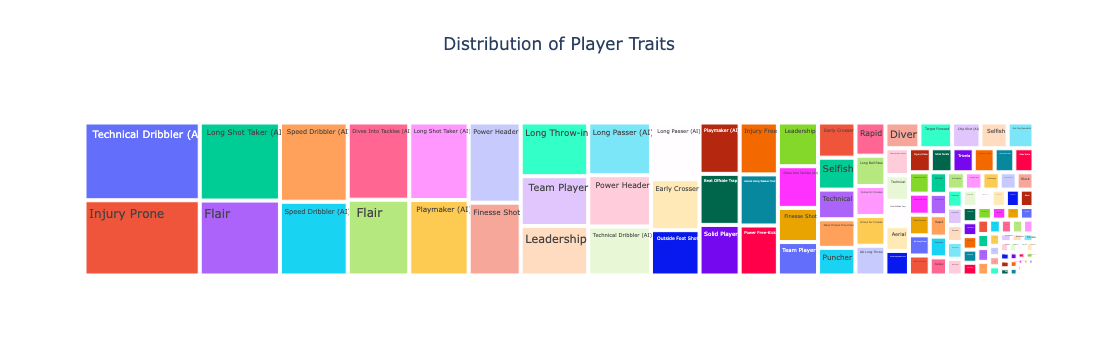

In [315]:
df_24_clean = df_clean[df_clean['fifa_version'] == 24.0].copy()
traits_series = df_clean['player_traits'].str.split(',', expand=True).stack()
trait_counts = traits_series.value_counts().reset_index()
trait_counts.columns = ['player_traits', 'count']
trait_counts_24 = trait_counts[trait_counts['player_traits'].isin(df_24_clean['player_traits'].unique())]
df_clean.to_csv('df_clean.csv', index=False)
trait_counts_24.to_csv('trait_counts_24.csv', index=False)

fig = px.treemap(
    trait_counts, 
    path=['player_traits'], 
    values='count',
    title='Distribution of Player Traits',
)
fig.update_traces(hovertemplate='Trait: %{label}<br>Count: %{value}<extra></extra>')
fig.update_layout(title='Distribution of Player Traits', title_x=0.5)
fig.show()

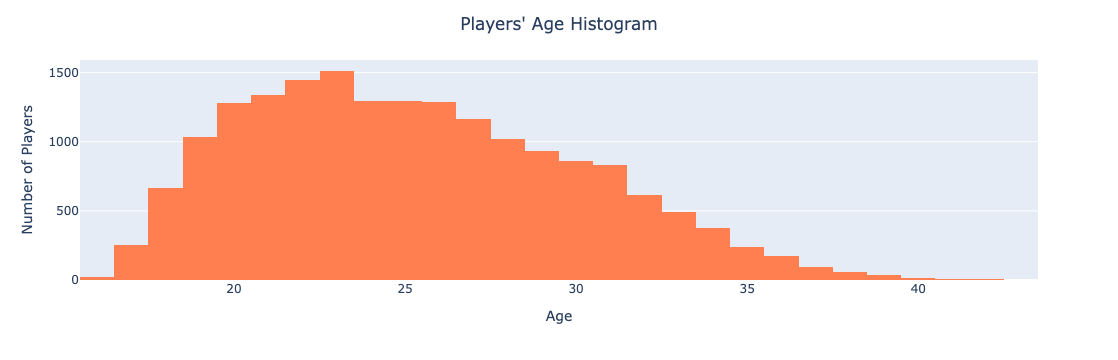

In [312]:
fig = px.histogram(df_24_clean, x='age', nbins=30, color_discrete_sequence=['coral'])
fig.update_layout(
    title='Players\' Age Histogram',
    title_x=0.5,
    xaxis_title='Age',
    yaxis_title='Number of Players',
    hovermode='x unified'
)
fig.show()

In [261]:
df_15 = df_clean[df_clean['fifa_version'] == 15.0]
df_16 = df_clean[df_clean['fifa_version'] == 16.0]
df_17 = df_clean[df_clean['fifa_version'] == 17.0]
df_18 = df_clean[df_clean['fifa_version'] == 18.0]
df_19 = df_clean[df_clean['fifa_version'] == 19.0]
df_20 = df_clean[df_clean['fifa_version'] == 20.0]
df_21 = df_clean[df_clean['fifa_version'] == 21.0]
df_22 = df_clean[df_clean['fifa_version'] == 22.0]
df_23 = df_clean[df_clean['fifa_version'] == 23.0]
df_24 = df_clean[df_clean['fifa_version'] == 24.0]

attributes = ['pace','shooting','passing','dribbling','defending','physic','overall', 'potential']

In [281]:
import plotly.graph_objects as go

def playergrowth(name):
    # Filter data for the player across different years
    data24 = df_24[df_24.short_name.str.contains(name, case=False, na=False)]
    data23 = df_23[df_23.short_name.str.contains(name, case=False, na=False)]
    data22 = df_22[df_22.short_name.str.contains(name, case=False, na=False)]
    data21 = df_21[df_21.short_name.str.contains(name, case=False, na=False)]
    data20 = df_20[df_20.short_name.str.contains(name, case=False, na=False)]
    data19 = df_19[df_19.short_name.str.contains(name, case=False, na=False)]
    data18 = df_18[df_18.short_name.str.contains(name, case=False, na=False)]
    data17 = df_17[df_17.short_name.str.contains(name, case=False, na=False)]
    data16 = df_16[df_16.short_name.str.contains(name, case=False, na=False)]
    data15 = df_15[df_15.short_name.str.contains(name, case=False, na=False)]

    df_24.to_csv('df_24.csv', index=False)
    attributes = ['pace', 'shooting', 'passing', 'dribbling', 'defending', 'physic', 'overall', 'potential']
    
    traces = []
    for data, year in zip(
    [data24, data23, data22, data21, data20, data19, data18, data17, data16, data15],
    ['2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017', '2016', '2015']):
        if not data.empty:
            short_name = data.iloc[0]['short_name']
            trace = go.Scatterpolar(
                r = [data['pace'].values[0], data['shooting'].values[0],
                     data['passing'].values[0], data['dribbling'].values[0],
                     data['defending'].values[0], data['physic'].values[0],
                     data['overall'].values[0], data['potential'].values[0]
                    ],
                theta = attributes,
                fill = 'toself',
                name = year
            )
            traces.append(trace)
        else:
            print(f"No data found for {name} in {year}")

    if traces:
        layout = go.Layout(
            polar=dict(
                radialaxis=dict(
                    visible=True,
                    range=[0, 100]
                )
            ),
            showlegend=True,
            title=f'Statistics related to {short_name} from 2015 to 2024'
        )
        fig = go.Figure(data=traces, layout=layout)
        fig.show()
    else:
        print(f"No data found for {name} in 2024")

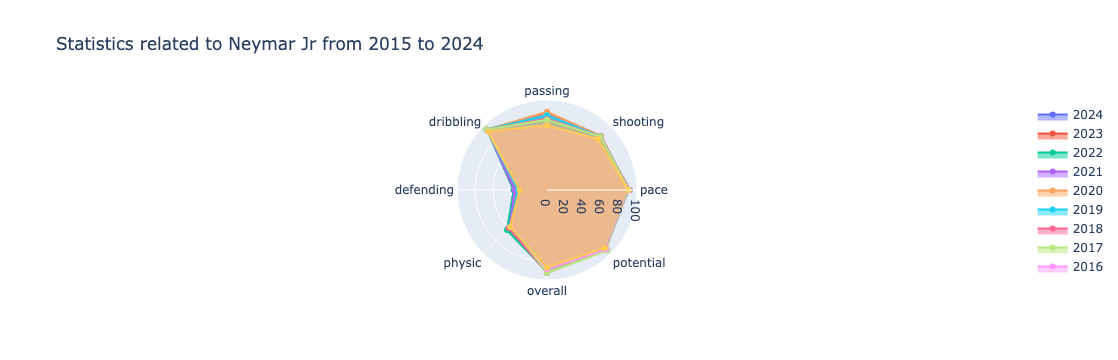

In [263]:
playergrowth('Neymar')

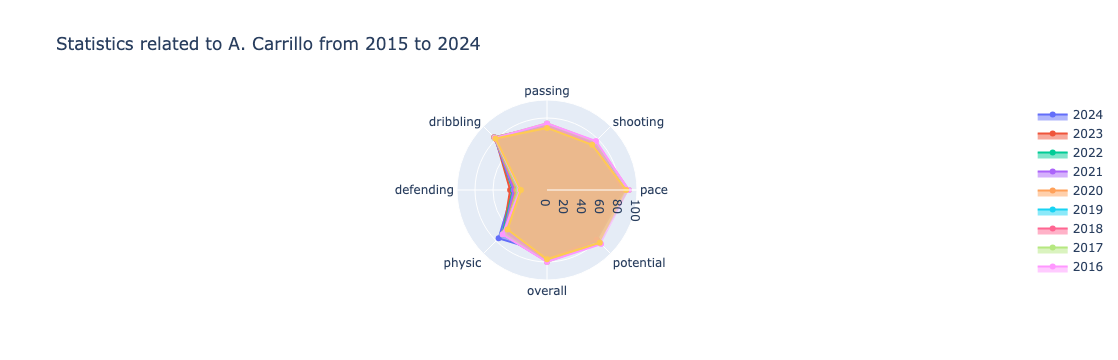

In [264]:
playergrowth('Carrillo')

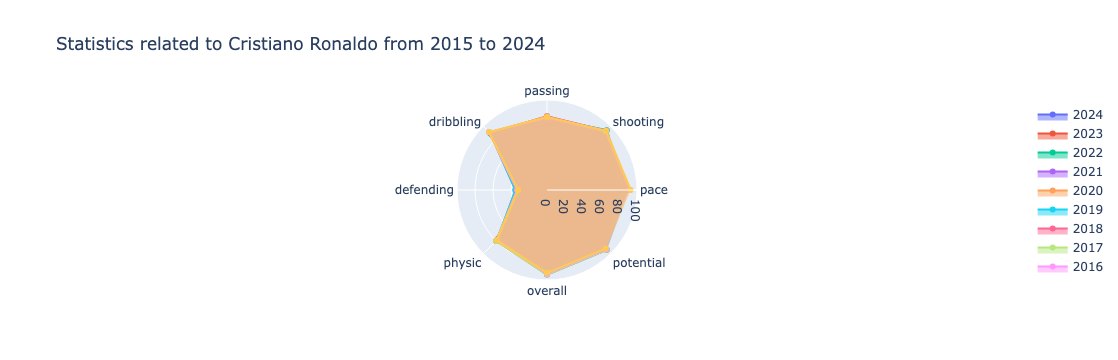

In [265]:
playergrowth('Cristiano Ronaldo')

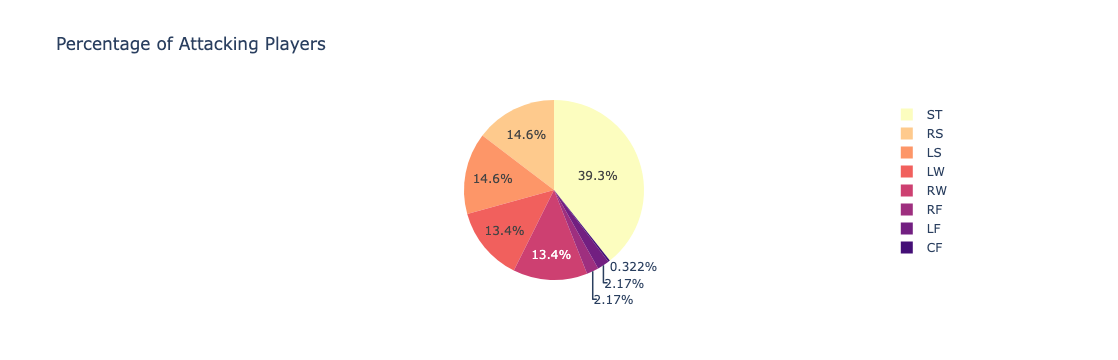

In [317]:
attack = ['RW', 'LW', 'ST', 'CF', 'LS', 'RS', 'RF', 'LF']
midfield = ['CAM', 'RCM', 'CDM', 'LDM', 'RM', 'LCM', 'LM', 'RDM', 'RAM', 'CM', 'LAM']
defence = ['LCB', 'RCB', 'LB', 'RB', 'CB', 'RWB', 'LWB', 'GK']

def categorize_position(position):
    if position in attack:
        return 'Attack'
    elif position in midfield:
        return 'Midfield'
    elif position in defence:
        return 'Defence'
    else:
        return 'Unknown'

df_clean['Position_Category'] = df_clean['club_position'].apply(categorize_position)
df_position_category = df_clean[['club_position', 'Position_Category']].drop_duplicates()
df_position_category.to_csv('df_position_category.csv', index=False)

att_p = df_24_clean.query('club_position in @attack')

fig = px.pie(att_p, names='club_position', color_discrete_sequence=px.colors.sequential.Magma_r,
            title='Percentage of Attacking Players')
fig.show()

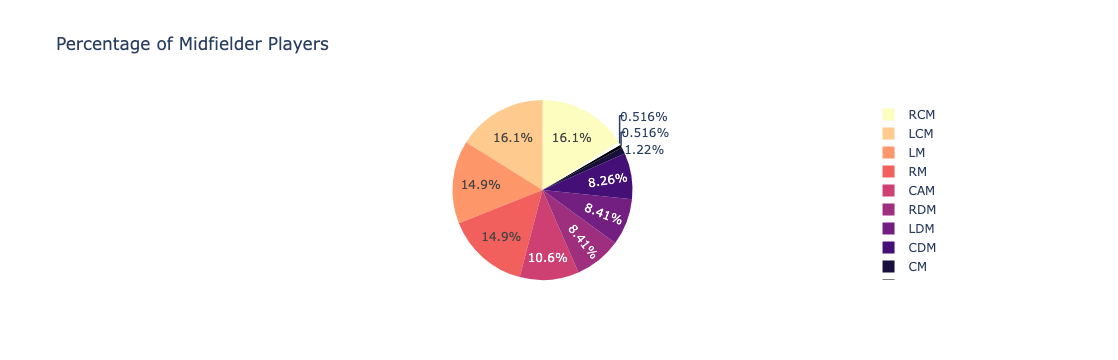

In [318]:
mid_p = df_24_clean.query('club_position in @mid')

fig = px.pie(mid_p, names='club_position', color_discrete_sequence=px.colors.sequential.Magma_r,
            title='Percentage of Midfielder Players')
fig.show()

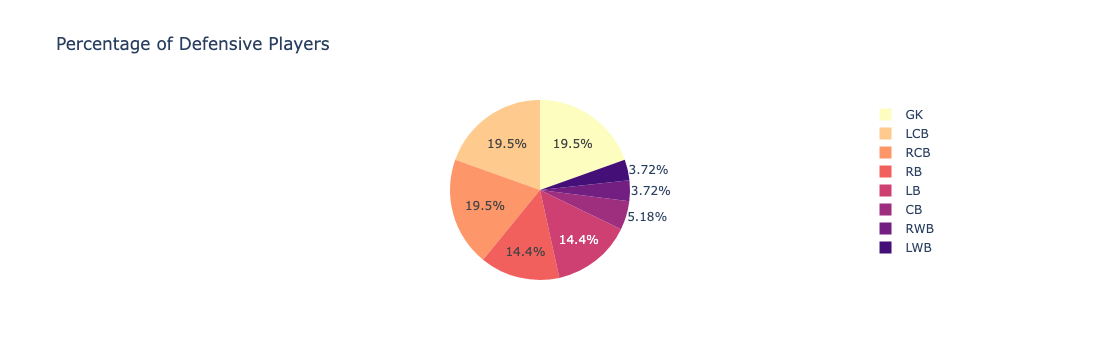

In [319]:
def_p = df_24_clean.query('club_position in @defence')

fig = px.pie(def_p, names='club_position', color_discrete_sequence=px.colors.sequential.Magma_r,
            title='Percentage of Defensive Players')
fig.show()

In [269]:
def pick_top_players(pos, value, nation=None):
    value_in_eur = value * 1_000_000
    column = 'Position_' + pos.upper()
    conditions = (df_24_clean[column] == 1) & (df_24_clean['value_eur'] <= value_in_eur)    
    if nation:
        conditions &= df_24_clean['nationality_name'] == nation
    target_players = df_24_clean[conditions][
        ['short_name', 'age', 'nationality_name', 'overall', 'potential', 'value_eur']
    ].sort_values(
        by=['potential', 'overall'], ascending=[False, False]
    ).head(5)
    return target_players

In [270]:
pick_top_players('lb',45)

,short_name,age,nationality_name,overall,potential,value_eur
201,J. Gvardiol,21,Croatia,82,88,44500000.0
205,Nuno Mendes,21,Portugal,82,87,43500000.0
847,F. Parisi,22,Italy,77,87,22500000.0
6197,J. Hato,17,Netherlands,68,87,2800000.0
852,D. Udogie,20,Italy,77,86,22000000.0


In [271]:
pick_top_players('cm',75)

,short_name,age,nationality_name,overall,potential,value_eur
142,Gavi,18,Spain,83,90,68500000.0
91,A. Tchouaméni,23,France,84,89,58500000.0
144,E. Fernández,22,Argentina,83,89,58000000.0
198,E. Camavinga,20,France,82,89,56500000.0
649,Gabri Veiga,21,Spain,78,89,31500000.0


In [272]:
pick_top_players('gk',25)

,short_name,age,nationality_name,overall,potential,value_eur
32,M. Neuer,37,Germany,87,87,9000000.0
4315,G. Restes,18,France,70,87,3600000.0
51,W. Szczęsny,33,Poland,86,86,22000000.0
77,K. Navas,36,Costa Rica,85,85,6000000.0
858,A. Trubin,21,Ukraine,77,85,20500000.0


In [273]:
pick_top_players('cdm',10, 'Peru')

,short_name,age,nationality_name,overall,potential,value_eur
4405,J. Castillo,22,Peru,70,79,3400000.0
6417,J. Pretell,24,Peru,68,75,2300000.0
2536,S. Peña,27,Peru,73,74,3500000.0
3840,J. Concha,24,Peru,71,74,2500000.0
4618,M. Távara,24,Peru,70,74,2300000.0


In [274]:
pick_top_players('rw',10, 'Brazil')

,short_name,age,nationality_name,overall,potential,value_eur
5205,Ângelo,18,Brazil,69,86,3500000.0
7233,Matheus Martins,19,Brazil,67,83,2600000.0
3600,Marquinhos,20,Brazil,71,81,4100000.0
6226,Pablo Felipe,19,Brazil,68,81,2900000.0
4365,Reinier,21,Brazil,70,80,3600000.0


In [275]:
def radar_chart_comparison(player_stats, similar_players_stats, attributes, player_name, similar_players_names):
    fig = go.Figure()
    fig.add_trace(go.Scatterpolar(
        r=player_stats.tolist() + player_stats[:1].tolist(),
        theta=attributes + [attributes[0]],
        fill='toself',
        name=player_name,
        line_color='blue'
    ))
    for stats, name in zip(similar_players_stats, similar_players_names):
        fig.add_trace(go.Scatterpolar(
            r=stats.tolist() + stats[:1].tolist(),
            theta=attributes + [attributes[0]],
            fill='toself',
            name=name
        ))
    buttons = [
        dict(
            method="update",
            label="All",
            args=[{"visible": [True] * (len(similar_players_names) + 1)},
                  {"title": f"Comparison: {player_name} vs All Similar Players"}]
        )
    ]
    for i, name in enumerate(similar_players_names):
        buttons.append(dict(
            method="update",
            label=name,
            args=[{"visible": [True] + [j == i for j in range(len(similar_players_names))]},
                  {"title": f"Comparison: {player_name} vs {name}"}]
        ))
    fig.update_layout(
        updatemenus=[dict(
            active=0,
            buttons=buttons,
            x=0.1,
            xanchor="left",
            y=1.15,
            yanchor="top"
        )],
        polar=dict(
            radialaxis=dict(
                visible=True,
                range=[0, 100]
            )),
        showlegend=True,
        title=f"Comparison: {player_name} vs All Similar Players"
    )
    fig.show()
def find_similar_players(player_name, num_players=5):
    attributes = [
        'pace', 'shooting', 'passing', 'dribbling', 
        'defending', 'physic'
    ]
    position_columns = [col for col in df_24_clean.columns if col.startswith('Position_')]
    target_player = df_24_clean[df_24_clean['short_name'].str.contains(player_name, case=False, na=False)]
    
    if target_player.empty:
        return f"Player containing '{player_name}' in their name not found."

    pos_conditions = (df_24_clean[position_columns] == target_player[position_columns].values).any(axis=1)
    filtered_df = df_24_clean[pos_conditions]
    
    scaler = StandardScaler()
    scaled_attributes = scaler.fit_transform(filtered_df[attributes])
    
    target_attributes = scaler.transform(target_player[attributes])
    similarities = cosine_similarity(target_attributes, scaled_attributes)
    
    filtered_df['similarity'] = similarities[0] * 100
    filtered_df['target_short_name'] = target_player['short_name'].values[0]
    
    similar_players = filtered_df.sort_values(by='similarity', ascending=False).head(num_players + 1)
    similar_players = similar_players[similar_players['short_name'] != target_player['short_name'].values[0]]
    similar_players['similarity'] = similar_players['similarity'].apply(lambda x: f"{x:.2f}%")
    target_player_stats = target_player[attributes].values[0]
    similar_players_stats = [row[attributes].values for _, row in similar_players.iterrows()]
    similar_players_names = similar_players['short_name'].tolist()

    radar_chart_comparison(target_player_stats, similar_players_stats, attributes, target_player['short_name'].values[0], similar_players_names)
    return similar_players[['short_name', 'age', 'overall', 'potential', 'value_eur', 'similarity']]

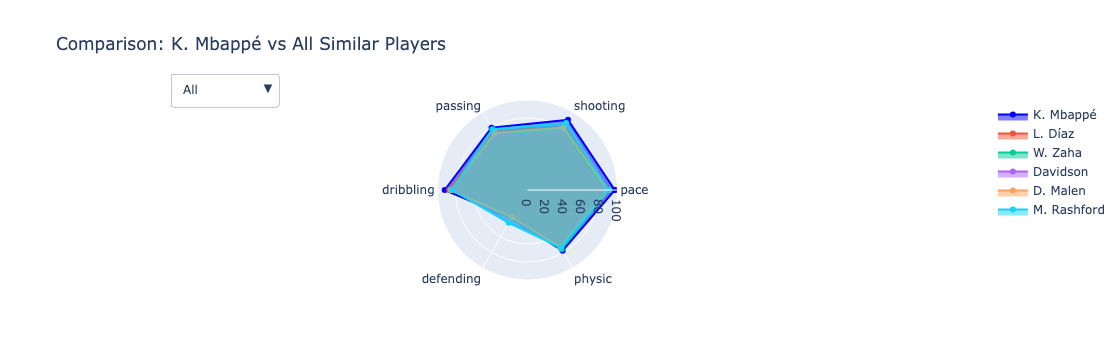

,short_name,age,overall,potential,value_eur,similarity
116,L. Díaz,26,84,85,49500000.0,99.62%
330,W. Zaha,30,81,81,25000000.0,99.59%
1386,Davidson,32,76,76,6000000.0,99.57%
227,D. Malen,24,82,84,39500000.0,99.55%
67,M. Rashford,25,85,88,71500000.0,99.41%


In [276]:
find_similar_players("Mbappé")

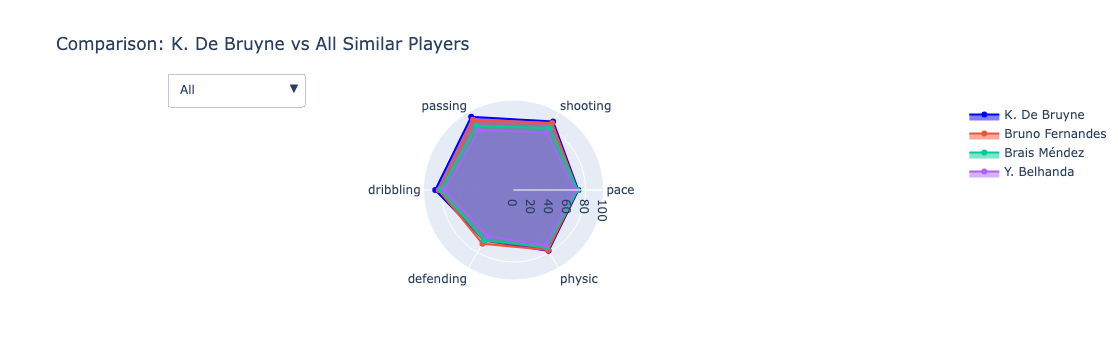

,short_name,age,overall,potential,value_eur,similarity
23,Bruno Fernandes,28,88,88,92000000.0,99.68%
308,Brais Méndez,26,81,82,30000000.0,99.59%
1628,Y. Belhanda,33,75,75,3500000.0,99.48%


In [277]:
find_similar_players("De Bruyne", 3)

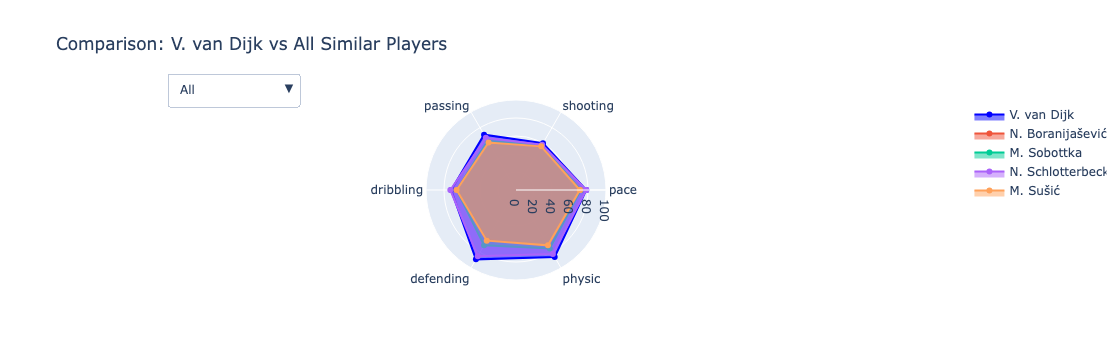

,short_name,age,overall,potential,value_eur,similarity
8301,N. Boranijašević,31,67,67,850000.0,99.53%
3422,M. Sobottka,29,72,72,2000000.0,99.31%
148,N. Schlotterbeck,23,83,88,49500000.0,99.30%
5968,M. Sušić,32,69,69,975000.0,99.19%


In [278]:
find_similar_players("van Dijk", 4)

In [283]:
def exponential_func(x, a, b):
    return a * np.exp(b * x)

df_filtered = df_24[['value_eur', 'overall']].dropna()
X = df_filtered['overall']
y = df_filtered['value_eur']

params, _ = curve_fit(exponential_func, X, y, p0=(1, 0.1))
df_filtered['predicted_value'] = exponential_func(X, *params)
r_squared = r2_score(y, df_filtered['predicted_value'])
print(f'R-squared: {r_squared:.4f}')

R-squared: 0.8296


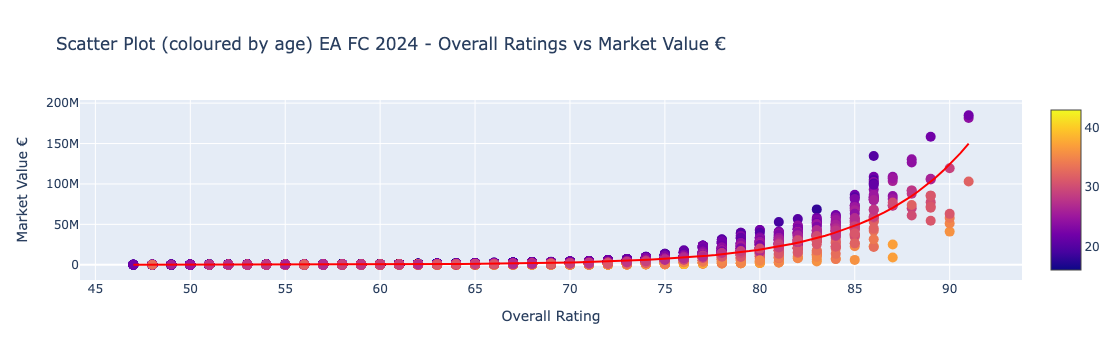

In [284]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x = df_24['overall'], y = df_24['value_eur'], mode = 'markers',
    marker = dict(
        size = 10,
        color = df_24['age'],
        showscale=True
    ),
    text = df_24_clean['short_name'],
    name='Players', showlegend=False
))

fig.add_trace(go.Scatter(
    x=np.linspace(df_filtered['overall'].min(), df_filtered['overall'].max(), 100),
    y=exponential_func(np.linspace(df_filtered['overall'].min(), df_filtered['overall'].max(), 100), *params),
    mode='lines', line=dict(color='red'), name='Exponential Fit', showlegend=False
))

fig.update_layout(
    title='Scatter Plot (coloured by age) EA FC 2024 - Overall Ratings vs Market Value €',
    xaxis_title='Overall Rating', yaxis_title='Market Value €',
)
fig.show()